# Schema field mapping

**Recipe 33** · Level 3 (Intermediate) · Decision type: `Choice`

Map source field descriptions to a bounded target schema, with `ambiguous` and `unmapped` outcomes, before Python validates the proposed mapping.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

A legacy-to-target schema mapper for a fabricated retailer's data export. Jev reads one source field at a time -- its name, its declared type, and a full description of what it actually holds -- and answers one `Choice` over the eight fields of a fixed target schema, plus `ambiguous` and `unmapped`. Jev never sees more than one field at a time, and never decides whether a proposed mapping is actually usable: Python does that afterward, checking that the declared type is compatible with the chosen target and that no two source fields were mapped to the same one. By the end you will have seen a field whose name is actively misleading and whose description resolves it anyway, two source fields whose descriptions both genuinely name the same target and whose answers still collide, and an evaluation that reports mapping accuracy and the conflicts validation catches, at the level of one field and at the level of a whole source batch.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` replays the 35 stored fields in `fixtures/responses.json` offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls to the same question definition and changes nothing else. `run_header` states which mode ran. Two labels may follow a number below. `(a pipeline check, not a Jev result)` marks a synthetic or scripted run; a recorded or live run does not print it, and its header says which mode ran. `(a selection step, not a reported result)` marks a line that is not a result to report, such as a number from `validation`, the split settings are chosen on, or a count of the items the frozen rule queues or would queue. A line with neither label, such as an individual answer or a per-example line, still comes from the mode the header names.

In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    accuracy,
    evaluate_outcomes,
    evaluate_selective,
    select_confidence_threshold,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ReviewQueue
from jev_cookbook.style import apply_style, plot_answer_probabilities, run_header, show_answer

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
# N for the header is the number of examples the metrics are about: validation and test. The
# three demo fields are shown but never scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: a number from the validation split is a selection step, not a
# result, in every run mode, so it carries this label unconditionally; a synthetic or scripted
# run adds `check` on top of it.
selection = " (a selection step, not a reported result)"

# Every source field needs at most one request. This cache makes sure a field shown
# individually and later scored in its split is decided once, so the whole notebook makes
# exactly 35 requests in live mode, never more.
answered = {}


def decide(example):
    """The one Choice answer for one source field, from one cached request."""
    if example.id not in answered:
        answered[example.id] = backend.decide(helpers.build_state(example.fields), questions)[
            "target"
        ]
    return answered[example.id]


def decisions_for(exs):
    """{example id: its Choice answer}, deciding each one (from the cache above)."""
    return {e.id: decide(e) for e in exs}


run_header(
    33,
    "Schema field mapping",
    backend=backend,
    n_examples=len(scored),
)

Recipe 33: Schema field mapping
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 32 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state is everything Jev sees, and Python builds it from one source field's own record. Each field in `fixtures/inputs.jsonl` carries `fields`: a `task_id` naming which fabricated legacy export batch it came from, the column's own `field_name`, its `declared_type`, and a full `description` of what the column actually contains. `build_state` passes on the name, the type and the description; `task_id` stays in Python, attached to the outcome afterward, because the one-to-one constraint that needs to see a field's whole batch is Python's job, never a request Jev answers.

In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
example = demo["d01"]
print("Python has:")
print(json.dumps(example.fields, indent=2))
state = helpers.build_state(example.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "task_id": "batch_d01",
  "field_name": "acct_label",
  "declared_type": "varchar",
  "description": "A short alphanumeric loyalty tier code such as GOLD-1, SILVER-2 or BRONZE-3, assigned when the customer enrolls in the rewards program. Despite the column's name, this field has never stored the account's own numeric identifier."
}
Jev sees:
{
  "field_name": "acct_label",
  "declared_type": "varchar",
  "description": "A short alphanumeric loyalty tier code such as GOLD-1, SILVER-2 or BRONZE-3, assigned when the customer enrolls in the rewards program. Despite the column's name, this field has never stored the account's own numeric identifier."
}


## The questions

There is one question, asked once per source field: which target schema field, if any, does this one correspond to? A `Choice` fits because the eight real targets, plus `ambiguous` and `unmapped`, are mutually exclusive and Jev should commit to exactly one (CONTRIBUTING.md section 3). Every option is built by Python from `helpers.TARGET_SCHEMA`, so the option list and the type each target expects can never drift apart, and each option's description is what Jev actually reads -- a field's own name is never trusted on its own. `unmapped` is there because a legacy export always carries columns the target schema has no place for; `ambiguous` is there because a column's own description sometimes really does fit more than one target equally well, and forcing a confident single guess in that case would hide the fact that a person needs to look at it. Each field is judged on its own, in one independent request: nothing about its batch, or any other field in it, is ever part of what Jev sees.

In [3]:
questions = helpers.build_questions()
target = questions["target"]
print(target.instructions)
print()
for name, description in target.criteria.items():
    print(f"{name}:")
    print(f"  {description}")

A source field from a legacy export is described below by its field name, its declared data type, and a full description of what it actually contains. Which target schema field does it correspond to? Judge by the description, not by the field name alone: a field's name can be a misleading holdover from an older system or a column that was repurposed, but its description is accurate. Choose ambiguous only when the description itself fits more than one target field equally well, and unmapped when no target field corresponds to this source field at all.

customer_email:
  customer_email (string): The customer's email address, used for account contact and order receipts.
customer_id:
  customer_id (integer): The internal numeric identifier assigned to the customer account.
order_total:
  order_total (decimal): The total monetary amount charged for the order, in the store's currency.
order_date:
  order_date (date): The calendar date the order was placed.
loyalty_tier:
  loyalty_tier (strin

## One answer up close

Before any aggregate, look at three fields that are shown but never scored, one for each of this recipe's hard cases. A `Choice` answer holds the chosen `choice`, a `probabilities` value for every option, and a [`confidence`](../../docs/glossary.md#confidence): the top probability rescaled by the number of options, `(p_max - 1/n) / (1 - 1/n)` (n = 10 here), so it is 0 when the top option has no more than an even share and 1 when one option holds all the probability. A [`provenance`](../../docs/glossary.md#provenance) line says where the answer came from, here always `synthetic`, since nothing in this recipe's fixtures came from a real call.

acct_label (varchar)
A short alphanumeric loyalty tier code such as GOLD-1, SILVER-2 or BRONZE-3, assigned when the customer enrolls in the rewards program. Despite the column's name, this field has never stored the account's own numeric identifier.
Choice: loyalty_tier (confidence 0.83)
  loyalty_tier      0.85  #################
  customer_email    0.02  
  customer_id       0.02  
  order_total       0.02  
  order_date        0.02  
  shipping_country  0.02  
  product_sku       0.02  
  is_gift_order     0.02  
  ambiguous         0.02  
  unmapped          0.02  
Provenance: synthetic


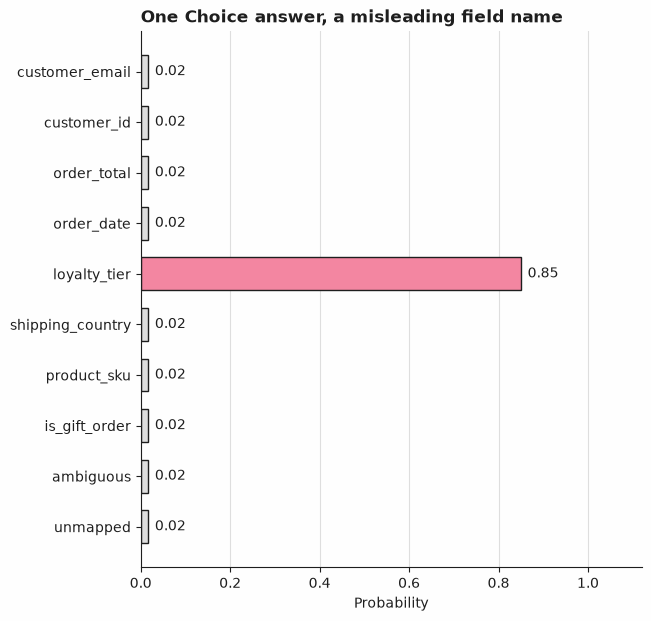

In [4]:
misleading = demo["d01"]
misleading_answer = decide(misleading)
print(f"{misleading.fields['field_name']} ({misleading.fields['declared_type']})")
print(misleading.fields["description"])
show_answer(misleading_answer)
plot_answer_probabilities(misleading_answer, title="One Choice answer, a misleading field name")

`acct_label`'s own name reads like an account identifier, but its description says plainly that the column has never stored one: it is a loyalty tier code. The stored answer names `loyalty_tier` anyway -- the lesson only lands because the description, not the name, is what decided it, and the description above is exactly what `build_state` passes through to Jev unchanged, nothing trimmed or paraphrased.

In [5]:
ambiguous_example = demo["d02"]
ambiguous_answer = decide(ambiguous_example)
print(f"{ambiguous_example.fields['field_name']} ({ambiguous_example.fields['declared_type']})")
print(ambiguous_example.fields["description"])
show_answer(ambiguous_answer)

support_region (varchar)
This column has been used inconsistently by different store locations: in about half of exports it holds the shipping country for the order, and in the other half it holds the customer's loyalty-program tier name instead; the export itself does not say which convention a given row follows.
Choice: ambiguous (confidence 0.33)
  ambiguous         0.40  ########
  loyalty_tier      0.30  ######
  shipping_country  0.30  ######
  customer_email    0.00  
  customer_id       0.00  
  order_total       0.00  
  order_date        0.00  
  product_sku       0.00  
  is_gift_order     0.00  
  unmapped          0.00  
Provenance: synthetic


`support_region`'s own description does not settle on one target field: by its own account, different store locations have used this column for two different things, `shipping_country` in some exports and `loyalty_tier` in others, and nothing here says which convention this row follows. The stored answer names `ambiguous`, with most of its probability still split between those same two candidates -- it is uncertain between exactly the two things the description itself is torn between, not uncertain in general. `ambiguous` is a [review](../../docs/glossary.md#review) outcome whatever its confidence (Python's part, below): it asks a person to pick between two real candidates the description does not settle, which is a deferral, never a final answer.

In [6]:
unmapped_example = demo["d03"]
unmapped_answer = decide(unmapped_example)
print(f"{unmapped_example.fields['field_name']} ({unmapped_example.fields['declared_type']})")
print(unmapped_example.fields["description"])
show_answer(unmapped_answer)

ticket_notes (varchar)
A short free-text note support agents attach to a customer record for their own follow-up; it is not read by any other system and has no corresponding column in the target schema.
Choice: unmapped (confidence 0.80)
  unmapped          0.82  ################
  customer_email    0.02  
  customer_id       0.02  
  order_total       0.02  
  order_date        0.02  
  loyalty_tier      0.02  
  shipping_country  0.02  
  product_sku       0.02  
  is_gift_order     0.02  
  ambiguous         0.02  
Provenance: synthetic


`ticket_notes` is a genuinely different case from either of the first two: its description says outright that nothing outside the support desk reads it, so there is no target field it could correspond to. `unmapped` is a complete answer to the question asked (which target field does this correspond to? none), not a deferral, so Python's part (below) gates it on confidence and checks its declared type exactly like a real target field -- rather than exempt it the way CONTRIBUTING.md section 4 would allow for a fallback option like this one.

## Python's part

Jev answers one field at a time; everything that needs more than one field is code. `helpers.gate_field` decides one field's outcome from its own answer alone, in order: `ambiguous` always goes to [review](../../docs/glossary.md#review), whatever its confidence, because it is a deferral; an option outside the fixed set is rejected defensively; a confidence below the [business threshold](../../docs/glossary.md#business-threshold) goes to review next; `unmapped` is then a complete, final answer at any remaining confidence; and a real target field is accepted only once its declared type matches that target's own type, checked by `helpers.normalize_type`. `helpers.apply_one_to_one` then looks at a whole batch's fields together, something no single request ever saw: any target chosen by more than one field is a conflict, and every field that proposed it is sent to review, not just one of them, because nothing in either field's own answer says which proposal (if either) is right. `helpers.compose_task` runs both stages for one batch; `helpers.rows_for_task` groups a split's fields by batch and `helpers.compose_split` applies `compose_task` to every batch, in order, so there is exactly one function that decides which fields are checked against which -- the notebook and `tests/test_helpers.py` both call it, never a private copy of the grouping. `tests/test_helpers.py` checks every branch of the gate, the one-to-one check on its own, the grouping on its own, and the whole pipeline together, including two tests that change only the model's answer or only a declared type on a real committed fixture and show that the composed outcome changes.

The [confidence gate](../../docs/glossary.md#confidence-gate) is the one setting this recipe chooses, on `validation`, and freezes before `test` is touched: among every cut whose [coverage](../../docs/glossary.md#coverage) (the share of fields a plain confidence gate alone would answer) is at least 85%, `select_confidence_threshold(min_coverage=0.85)` picks the one with the highest accuracy on the fields it answers (ties toward the lower threshold, i.e. more coverage). The alternative, asking for perfect validation accuracy (`target_accuracy=1.0`), does not avoid selecting for a number -- it still maximises accuracy subject to a floor, just a floor of 1.0 instead of a coverage share -- so the real difference is only in which floor is asked for, and `min_coverage` is preferred here because a coverage floor is a property of how much of `validation` the gate may ignore, not a demand that it be perfect.

Two things about what that cell prints are worth saying plainly. On this fixture set the two objectives do not merely agree in spirit: `target_accuracy=1.0` selects the **same** gate, so the choice between them moves no number here and the preference above is an argument about which floor to ask for rather than about which cut it yields (`tests/test_helpers.py::test_both_threshold_objectives_select_the_same_gate_on_validation` pins that, since it is a property of the committed answers rather than of either function). And the gate-only accuracy printed beside the gate is a ceiling this fixture set allows rather than an independent check of it: the objective maximises accuracy subject to the coverage floor, so whenever some cut at or above that floor answers only correct fields, the chosen cut is one of them. Read it the way the conflict counts further below are read -- as what this pool permits, not as what the gate would do on data it was not chosen on.

In [7]:
val_examples = select_split(examples, "validation")
val_decisions = decisions_for(val_examples)
val_raw_correct = [val_decisions[e.id].choice == labels[e.id] for e in val_examples]
val_confidence = [val_decisions[e.id].confidence for e in val_examples]
MIN_COVERAGE = 0.85
threshold = select_confidence_threshold(val_raw_correct, val_confidence, min_coverage=MIN_COVERAGE)
print(f"chosen confidence gate, frozen from here on: {threshold:.4f}{selection}{check}")

# What MIN_COVERAGE actually bounds: the confidence gate alone, applied to the raw choice, with
# none of gate_field's other branches (ambiguous, a foreign option, the declared-type check) or
# apply_one_to_one's one-to-one check running at all. This is not the full rule's own coverage,
# reported in "Evaluation" below -- see the note there for why the two differ.
gate_only = evaluate_selective(val_raw_correct, val_confidence, threshold)
print(
    f"gate-only coverage and accuracy at this cut: {gate_only.coverage:.4f}, "
    f"{gate_only.accuracy:.4f}{selection}{check}"
)

chosen confidence gate, frozen from here on: 0.7778 (a selection step, not a reported result) (a pipeline check, not a Jev result)
gate-only coverage and accuracy at this cut: 0.8750, 1.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)


### The one-to-one constraint catches a collision neither request could see

`batch_v06` has two source fields, `ship_to_cc` and `alt_country_note`. Each is judged on its own, and each one's own description genuinely does read as `shipping_country` -- the two cells below print both fields' states, and neither one names the other: `alt_country_note`'s own description says it is an acknowledged duplicate of another column, kept side by side in the export, that also records the shipping country. Both fields' [gold labels](../../docs/glossary.md#gold-label) are `shipping_country`, and both of the model's stored answers agree with each other, confidently and correctly. That is exactly the situation the one-to-one constraint exists for: Python holds the whole batch at once, and `shipping_country` cannot be both fields' target in the mapping it hands off, so both are sent to review even though neither one is wrong -- the conflict costs something here even when every individual answer was right, because nothing in either field's own answer says which of two correct proposals should be the one that is kept.

In [8]:
conflict_rows = helpers.rows_for_task(val_examples, val_decisions)["batch_v06"]
for field_id, field_name, _declared_type, field_answer in conflict_rows:
    print(
        f"{field_id} ({field_name}): choice={field_answer.choice}, "
        f"confidence={field_answer.confidence:.4f}{check}"
    )
for outcome in helpers.compose_task("batch_v06", conflict_rows, threshold):
    print(f"{outcome.field_id}: {outcome.outcome} ({outcome.reason}){check}")

v11-conflict (ship_to_cc): choice=shipping_country, confidence=0.8333 (a pipeline check, not a Jev result)
v12-conflict (alt_country_note): choice=shipping_country, confidence=0.8333 (a pipeline check, not a Jev result)
v11-conflict: review (one-to-one constraint violated) (a pipeline check, not a Jev result)
v12-conflict: review (one-to-one constraint violated) (a pipeline check, not a Jev result)


## Evaluation

The gate was chosen and frozen above, on `validation`. This section reports what the frozen rule does, at two levels: at the level of one field (per question), how often the final mapping matches the field's gold label; at the level of a whole batch (task level), how often every field of that batch was accepted with the right target, since a batch's mapping is only as good as its worst field. `helpers.compose_split` is applied to every field of `validation` and of `test` (never a separate reimplementation of the grouping or of `compose_task`'s two stages), and every count below comes from what it actually returns, via `helpers.field_accepted_and_correct` and `helpers.task_accepted_and_correct`. `helpers.conflict_count` reports, separately, how many fields were sent to review specifically for the one-to-one constraint -- this recipe's count of the conflicts caught by the one-to-one check. In an offline run every `test` number is a check that the pipeline works, and says so; every `validation` number, in every run mode, is a selection step rather than a reported result.

In [9]:
val_outcomes = helpers.compose_split(val_examples, val_decisions, threshold)
val_gold = [labels[e.id] for e in val_examples]
val_raw_choice = [val_decisions[e.id].choice for e in val_examples]

print(f"validation, {len(val_examples)} fields{selection}{check}")
print(
    f"  raw mapping accuracy (ungated): {accuracy(val_gold, val_raw_choice):.4f}{selection}{check}"
)

val_field_accepted, val_field_correct = helpers.field_accepted_and_correct(val_outcomes, labels)
val_field_result = evaluate_outcomes(val_field_accepted, val_field_correct)
print(
    f"  field level: accepted {val_field_result.n_answered} of {val_field_result.n_total} "
    f"(coverage {val_field_result.coverage:.4f}), accuracy among accepted "
    f"{val_field_result.accuracy:.4f}, risk {val_field_result.risk:.4f}{selection}{check}"
)
print(
    "  (this coverage is lower than the gate-only coverage above because three further "
    f"review branches -- ambiguous, a declared-type mismatch, a one-to-one conflict -- also "
    f"hold fields back after the gate){selection}{check}"
)

val_task_ids, val_task_accepted, val_task_correct = helpers.task_accepted_and_correct(
    val_outcomes, labels
)
val_task_result = evaluate_outcomes(val_task_accepted, val_task_correct)
print(
    f"  task level: accepted {val_task_result.n_answered} of {val_task_result.n_total} "
    f"(coverage {val_task_result.coverage:.4f}), accuracy among accepted "
    f"{val_task_result.accuracy:.4f}, risk {val_task_result.risk:.4f}{selection}{check}"
)
val_conflicts = helpers.conflict_count(val_outcomes)
print(f"  conflicts caught by the one-to-one check: {val_conflicts}{selection}{check}")
print(
    f"  ({val_conflicts} is a ceiling this fixture set sets, not an estimate: validation has "
    f"exactly one conflicting pair, both members above the frozen gate, so the one-to-one "
    f"check can never catch more than {val_conflicts} here){selection}{check}"
)

validation, 16 fields (a selection step, not a reported result) (a pipeline check, not a Jev result)
  raw mapping accuracy (ungated): 0.9375 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  field level: accepted 11 of 16 (coverage 0.6875), accuracy among accepted 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  (this coverage is lower than the gate-only coverage above because three further review branches -- ambiguous, a declared-type mismatch, a one-to-one conflict -- also hold fields back after the gate) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  task level: accepted 5 of 8 (coverage 0.6250), accuracy among accepted 1.0000, risk 0.0000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  conflicts caught by the one-to-one check: 2 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  (2 is a ceiling this fixt

`validation`'s raw mapping accuracy printed just above is not vacuous: one of its sixteen fields is genuinely wrong (`promo_code_applied` in `batch_v03`), and it is caught, by the confidence gate -- its stored answer is deliberately unconfident. The other fifteen raw answers are correct, `ship_to_cc` and `alt_country_note` included: both genuinely name `shipping_country`, and both are still sent to review, by the one-to-one check, not because either is wrong but because the mapping can only keep one of them. That cleanliness is a property of how this fixture set was built to exercise both mechanisms on `validation`, not a guarantee the next section repeats: `test` is where this recipe's frozen gate actually meets a mistake neither mechanism catches.

In [10]:
test_examples = select_split(examples, "test")
test_decisions = decisions_for(test_examples)
test_outcomes = helpers.compose_split(test_examples, test_decisions, threshold)
test_gold = [labels[e.id] for e in test_examples]
test_raw_choice = [test_decisions[e.id].choice for e in test_examples]

print(f"test, {len(test_examples)} fields, gate {threshold:.4f} frozen{check}")
print(f"  raw mapping accuracy (ungated): {accuracy(test_gold, test_raw_choice):.4f}{check}")

test_field_accepted, test_field_correct = helpers.field_accepted_and_correct(test_outcomes, labels)
test_field_result = evaluate_outcomes(test_field_accepted, test_field_correct)
print(
    f"  field level: accepted {test_field_result.n_answered} of {test_field_result.n_total} "
    f"(coverage {test_field_result.coverage:.4f}), accuracy among accepted "
    f"{test_field_result.accuracy:.4f}, risk {test_field_result.risk:.4f}{check}"
)

test_task_ids, test_task_accepted, test_task_correct = helpers.task_accepted_and_correct(
    test_outcomes, labels
)
test_task_result = evaluate_outcomes(test_task_accepted, test_task_correct)
print(
    f"  task level: accepted {test_task_result.n_answered} of {test_task_result.n_total} "
    f"(coverage {test_task_result.coverage:.4f}), accuracy among accepted "
    f"{test_task_result.accuracy:.4f}, risk {test_task_result.risk:.4f}{check}"
)
test_conflicts = helpers.conflict_count(test_outcomes)
print(f"  conflicts caught by the one-to-one check: {test_conflicts}{check}")
print(
    f"  ({test_conflicts} is a ceiling this fixture set sets, not an estimate: test has "
    f"exactly one conflicting pair, both members above the frozen gate, so the one-to-one "
    f"check can never catch more than {test_conflicts} here){check}"
)

test, 16 fields, gate 0.7778 frozen (a pipeline check, not a Jev result)
  raw mapping accuracy (ungated): 0.9375 (a pipeline check, not a Jev result)
  field level: accepted 12 of 16 (coverage 0.7500), accuracy among accepted 0.9167, risk 0.0833 (a pipeline check, not a Jev result)
  task level: accepted 5 of 8 (coverage 0.6250), accuracy among accepted 0.8000, risk 0.2000 (a pipeline check, not a Jev result)
  conflicts caught by the one-to-one check: 2 (a pipeline check, not a Jev result)
  (2 is a ceiling this fixture set sets, not an estimate: test has exactly one conflicting pair, both members above the frozen gate, so the one-to-one check can never catch more than 2 here) (a pipeline check, not a Jev result)


Test confusion matrix, gold rows by predicted columns (raw choice, ungated) (a pipeline check, not a Jev result):
  predicted ->             customer_email       customer_id       order_total        order_date      loyalty_tier  shipping_country       product_sku     is_gift_order         ambiguous          unmapped (a pipeline check, not a Jev result)
  gold customer_email                   1                 0                 0                 0                 0                 0                 0                 0                 0                 0 (a pipeline check, not a Jev result)
  gold customer_id                      0                 1                 0                 0                 0                 0                 0                 0                 0                 0 (a pipeline check, not a Jev result)
  gold order_total                      0                 0                 1                 0                 0                 0                 0              

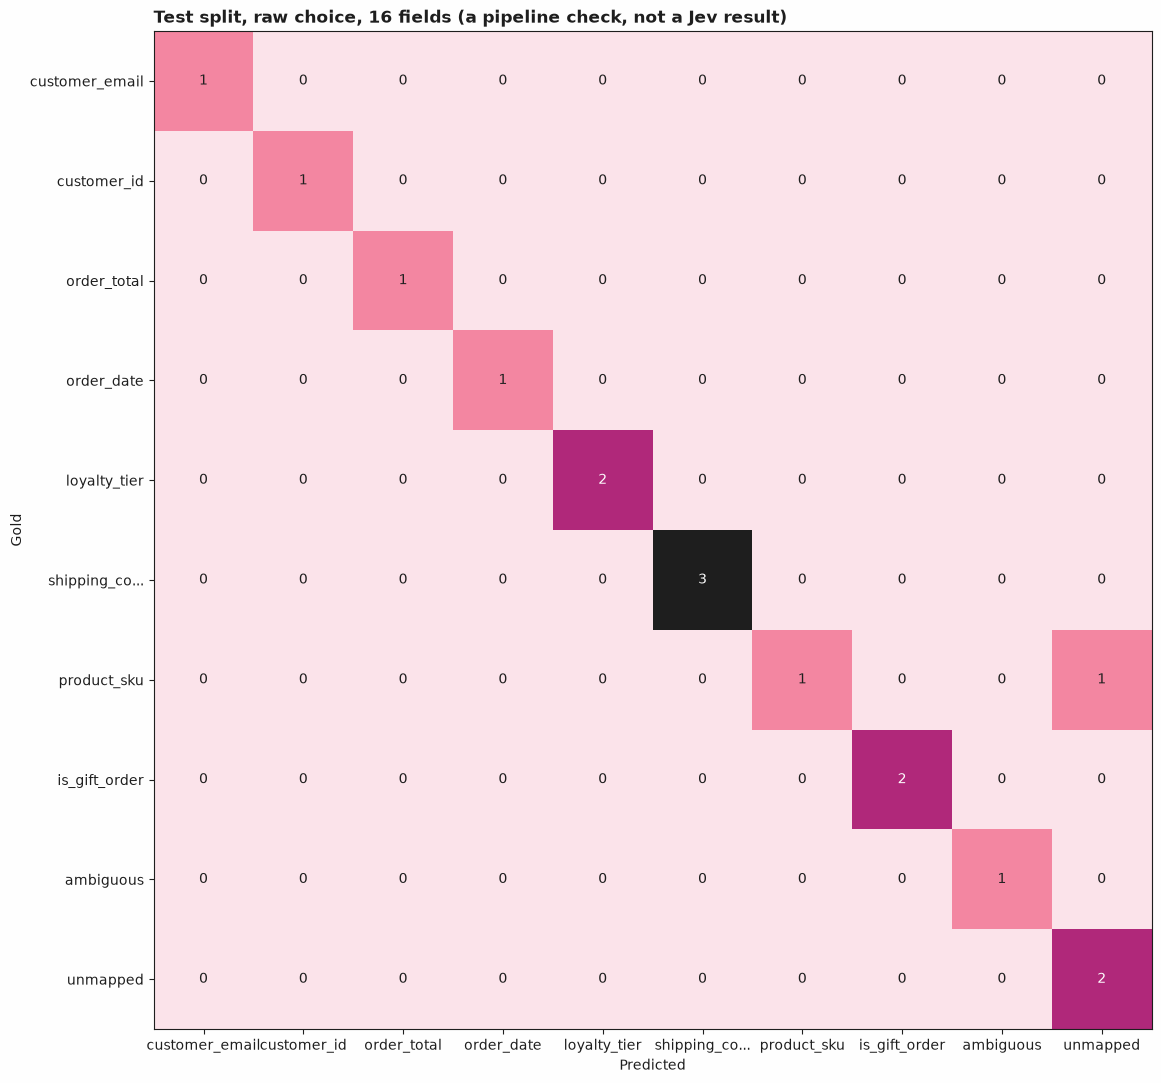

In [11]:
from jev_cookbook.evaluation import confusion_matrix
from jev_cookbook.style import plot_confusion_matrix

all_options = list(questions["target"].criteria)
matrix = confusion_matrix(test_gold, test_raw_choice, labels=all_options)
width = max(len(label) for label in matrix.labels)
leader_width = max(width + len("gold "), len("predicted ->"))
header = "  ".join(f"{label:>{width}s}" for label in matrix.labels)
print(f"Test confusion matrix, gold rows by predicted columns (raw choice, ungated){check}:")
print(f"  {'predicted ->':<{leader_width}s}  {header}{check}")
for gold_label, row in zip(matrix.labels, matrix.matrix.tolist(), strict=True):
    counts = "  ".join(f"{count:{width}d}" for count in row)
    leader = f"gold {gold_label:<{width}s}"
    print(f"  {leader:<{leader_width}s}  {counts}{check}")
plot_confusion_matrix(matrix, title=f"Test split, raw choice, {len(test_examples)} fields{check}")

In [12]:
print(f"test fields accepted with the wrong target{check}:")
for outcome in test_outcomes:
    if outcome.outcome == helpers.ACCEPTED and outcome.final_target != labels[outcome.field_id]:
        wrong_answer = test_decisions[outcome.field_id]
        print(
            f"  {outcome.field_id} ({outcome.field_name}, {outcome.task_id}): gold "
            f"{labels[outcome.field_id]!r}, accepted {outcome.final_target!r} "
            f"(confidence {wrong_answer.confidence:.4f}){check}"
        )

test fields accepted with the wrong target (a pipeline check, not a Jev result):
  t16-wrong (sku_note, batch_t08): gold 'product_sku', accepted 'unmapped' (confidence 0.9111) (a pipeline check, not a Jev result)


`sku_note` names `unmapped`, confidently, for a field whose description names the ordered product's own SKU, recorded as a secondary copy by an older point-of-sale terminal; the gold target is `product_sku`. "A duplicated secondary copy has no place in the target schema" is a mistake a model could plausibly make from that description, and nothing structural catches it: `unmapped` has no declared type to check, and no other field in `batch_t08` was also mapped to a real target it could collide with, so there is no type mismatch and no one-to-one conflict for Python's validation to flag. Its confidence, printed above, clears the gate chosen on `validation` comfortably: the gate was tuned against a mistake that was deliberately unconfident, and this one is not, so it is the field-level and task-level [risk](../../docs/glossary.md#risk) reported above, not a flaw in either stage's arithmetic.

risk-coverage sweep over the confidence gate, test (confidence-only view) (a pipeline check, not a Jev result):
  gate 0.9111: coverage 0.0625, accuracy 0.0000, risk 1.0000 (a pipeline check, not a Jev result)
  gate 0.8889: coverage 0.1875, accuracy 0.6667, risk 0.3333 (a pipeline check, not a Jev result)
  gate 0.8667: coverage 0.3125, accuracy 0.8000, risk 0.2000 (a pipeline check, not a Jev result)
  gate 0.8444: coverage 0.4375, accuracy 0.8571, risk 0.1429 (a pipeline check, not a Jev result)
  gate 0.8333: coverage 0.5625, accuracy 0.8889, risk 0.1111 (a pipeline check, not a Jev result)
  gate 0.8222: coverage 0.7500, accuracy 0.9167, risk 0.0833 (a pipeline check, not a Jev result)
  gate 0.8000: coverage 0.8750, accuracy 0.9286, risk 0.0714 (a pipeline check, not a Jev result)
  gate 0.7778: coverage 0.9375, accuracy 0.9333, risk 0.0667 (a pipeline check, not a Jev result)
  gate 0.3556: coverage 1.0000, accuracy 0.9375, risk 0.0625 (a pipeline check, not a Jev result)


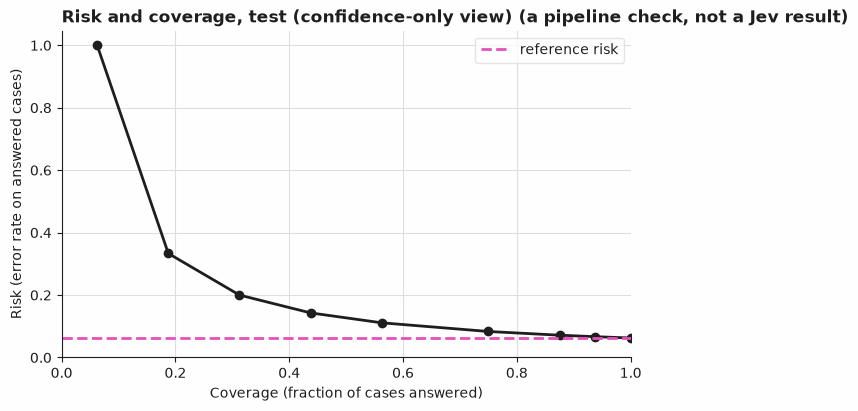

In [13]:
from jev_cookbook.evaluation import selective_curve
from jev_cookbook.style import plot_risk_coverage

test_raw_correct = [c == g for c, g in zip(test_raw_choice, test_gold, strict=True)]
test_confidence = [test_decisions[e.id].confidence for e in test_examples]
curve = selective_curve(test_raw_correct, test_confidence)
print(f"risk-coverage sweep over the confidence gate, test (confidence-only view){check}:")
for t, cov, acc, risk in zip(
    curve.thresholds, curve.coverage, curve.accuracy, curve.risk, strict=True
):
    print(f"  gate {t:.4f}: coverage {cov:.4f}, accuracy {acc:.4f}, risk {risk:.4f}{check}")
plot_risk_coverage(
    curve,
    reference_risk=1 - accuracy(test_gold, test_raw_choice),
    title=f"Risk and coverage, test (confidence-only view){check}",
)

This curve sweeps the confidence gate alone, over every field's raw choice, ignoring the declared-type check and the one-to-one constraint entirely -- it is the confidence-only view `docs/evaluation.md` describes, shown here only to place the frozen gate (0.7778) on the curve, not as a second reported risk figure. `helpers.compose_split`'s own outcomes, reported above, are what this recipe actually evaluates: a rule with review branches beyond a confidence gate is read from its own outcomes (`evaluate_outcomes`), never reconstructed from this sweep.

In [14]:
queue = ReviewQueue()
helpers.submit_reviews(queue, val_outcomes, val_decisions)
helpers.submit_reviews(queue, test_outcomes, test_decisions)
print(f"review queue, both splits, {len(queue)} fields{check}:")
for item in queue.to_dicts():
    print(
        f"  #{item['id']} {item['item']['field_id']} ({item['item']['task_id']}): "
        f"{item['reason']}{check}"
    )

review queue, both splits, 9 fields (a pipeline check, not a Jev result):
  #0 v05-ambiguous (batch_v03): the model found more than one target field equally plausible (a pipeline check, not a Jev result)
  #1 v06-wrong (batch_v03): confidence below the threshold (a pipeline check, not a Jev result)
  #2 v07-type (batch_v04): declared type does not match the target field's type (a pipeline check, not a Jev result)
  #3 v11-conflict (batch_v06): one-to-one constraint violated (a pipeline check, not a Jev result)
  #4 v12-conflict (batch_v06): one-to-one constraint violated (a pipeline check, not a Jev result)
  #5 t05-ambiguous (batch_t03): the model found more than one target field equally plausible (a pipeline check, not a Jev result)
  #6 t06-type (batch_t04): declared type does not match the target field's type (a pipeline check, not a Jev result)
  #7 t10-conflict (batch_t06): one-to-one constraint violated (a pipeline check, not a Jev result)
  #8 t11-conflict (batch_t06): one-to-o

Every field above is a [review](../../docs/glossary.md#review) outcome, not an action: this recipe applies no mapping and changes no schema, it only queues the field, with the model's own choice attached, for a person to resolve. Four distinct reasons appear in the queue above: `ambiguous` (a deferral, by design, on both splits), a type mismatch (the model's choice was semantically right and still held back), a one-to-one conflict (two correct, colliding proposals), and plain low confidence (the one validation mistake the gate was tuned to catch). Nothing here is a [coverage](../../docs/glossary.md#coverage) number; it is the other side of it.

## What was and was not measured

Measured: that the pipeline runs end to end, and that the confidence gate, the declared-type check and the one-to-one constraint behave as designed on 32 scored fields across 8 `validation` batches and 8 `test` batches (plus 3 more fields in 1 more batch, shown in this notebook but never scored -- the counts below). Not measured: anything about how Jev performs, how fast it is, or what it costs. The stored answers in the offline run are written by hand as probabilities, with at least one of them wrong on purpose and confident enough to clear the frozen gate on `test`, so every number above describes this fixture set and not a model.

In [15]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test fields{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test fields")
demo_count = len(examples) - len(scored)
val_batches = {e.fields["task_id"] for e in scored if e.split == "validation"}
test_batches = {e.fields["task_id"] for e in scored if e.split == "test"}
demo_batches = {e.fields["task_id"] for e in examples if e.split == "demo"}
print(
    f"Batches: {len(val_batches)} validation, {len(test_batches)} test, "
    f"{len(demo_batches)} demo{check}"
)
print(
    f"Requests to decisions: {len(scored)} scored fields + {demo_count} demo fields = "
    f"{len(answered)} requests, 1 question each = {len(answered)} judgments.{check}"
)

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 16 validation and 16 test fields (a pipeline check, not a Jev result)
Batches: 8 validation, 8 test, 1 demo (a pipeline check, not a Jev result)
Requests to decisions: 32 scored fields + 3 demo fields = 35 requests, 1 question each = 35 judgments. (a pipeline check, not a Jev result)


## Next steps

- Add a third source field to `batch_v01` in `build_fixtures.py` whose stored answer also names `loyalty_tier` confidently, run `python build_fixtures.py`, and re-run this notebook: `helpers.apply_one_to_one` sends all three fields that named `loyalty_tier` to review, not just two, even though each field's own request still looks fine in isolation.
- Raise `MIN_COVERAGE` in "Python's part" above `0.85` and re-run: at `0.90` the frozen gate falls sharply, because nothing in `validation`'s sixteen fields answers that much more of the split at a nearby cut -- print `selective_curve(val_raw_correct, val_confidence)` to see exactly which confidences are, and are not, available for a looser target to land on.
- Neighbouring recipes: [`04-support-ticket-routing`](../04-support-ticket-routing/) (a single `Choice` composed with a Python rule) and [`22-cmdb-asset-matching`](../22-cmdb-asset-matching/) (a `Choice` with a fallback option and a simulated backlog), two other shapes of "the model proposes, Python validates."
